In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# Week-3

**Note to Learners**:

- For questions that involve plotting, just enter $0$ as the answer in the portal.
- For numerical questions, there are two parts. The first part expects you to compute some quantity, say a parameter of a machine learning model. The second part will require you to convert this quantity (if it is not a scalar) into a scalar so that it can be entered as the answer on the portal to the corresponding NAT question.



## Dataset

Run the cell given below to generate the data-matrix $\mathbf{X}$, which is of shape $(n, d)$, where $n$ denotes the number of samples and $d$ denotes the number of features. You will be using this dataset for the rest of the assignment.

**Do not edit this cell.**

In [ ]:
np.random.seed(0)

N = 2000
data1 = np.random.randn(N//3,2) + np.array([2,2])
data2 = np.random.randn(N//3,2) + np.array([-3,-3])
data3 = np.random.randn(N//3,2) + np.array([-5,3])
X = np.concatenate((data1, data2, data3))


## Problem 1
How many samples are there in the dataset?



## Solution

In [ ]:
num_samples = X.shape[0]
print(f"Number of samples in the dataset: {num_samples}")

Number of samples in the dataset: 1998


## Problem 2

How many features are there in the dataset?


## Solution

In [ ]:
num_features = X.shape[1]
print(f"Number of features in the dataset: {num_features}")

Number of features in the dataset: 2


## Problem 3
Plot the dataset using matplotlib.



## Solution

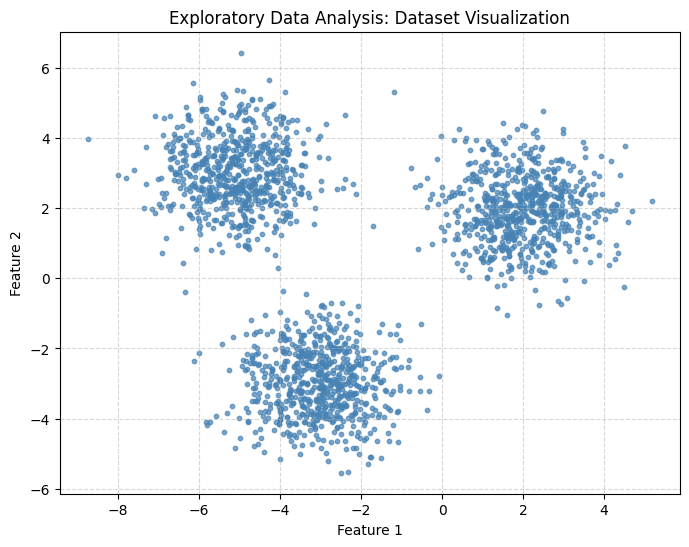

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=10, alpha=0.7, color='steelblue')
plt.title("Exploratory Data Analysis: Dataset Visualization")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Instruction

Assume k = 3. Take the data points with indices 200, 800 and 1200 in X to be the initial cluster centers.


In [ ]:
k = 3
initial_centers = X[[200, 800, 1200]]
print("Initial cluster centers selected:")
print(initial_centers)

Initial cluster centers selected:
[[ 1.40134606  0.88410301]
 [-2.56922887 -3.14989159]
 [-2.84782302 -3.37412632]]


## Problem 4

Write a function `assign_clusters(X, k, cluster_centers)` that assigns a cluster to each data point as per their distance from each cluster centre and returns a vector `z`, where $z[i] \in \{0, 1, 2\}$.

What is the mean of the values in vector `z`? Provide the answer correct up to three decimal places.



## Solution

In [ ]:
def assign_clusters(X, k, cluster_centers):
    # Calculate Euclidean distance from each point to each center
    # Shape of X is (N, 2), centers is (k, 2)
    # We compute distances of shape (N, k)
    distances = np.linalg.norm(X[:, np.newaxis, :] - cluster_centers, axis=2)
    # Assign to the nearest cluster center
    z = np.argmin(distances, axis=1)
    return z

z = assign_clusters(X, k, initial_centers)
mean_z = np.mean(z)
print(f"Mean of the cluster assignment vector z: {mean_z:.3f}")

Mean of the cluster assignment vector z: 0.711


## Problem 5

Plot the data points, with different color for different clusters.


## Solution

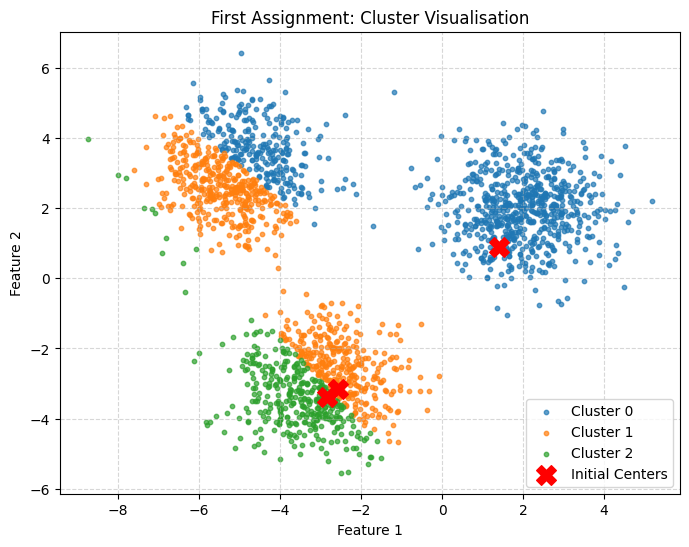

In [ ]:
plt.figure(figsize=(8, 6))
for cluster_idx in range(k):
    cluster_data = X[z == cluster_idx]
    plt.scatter(cluster_data[:, 0], cluster_data[:, 1], label=f'Cluster {cluster_idx}', s=10, alpha=0.7)
plt.scatter(initial_centers[:, 0], initial_centers[:, 1], c='red', marker='X', s=200, label='Initial Centers')
plt.title("First Assignment: Cluster Visualisation")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Problem 6
Write a function `compute_cluster_centers(X, z, k)` that computes the clusters' centers as per z and returns `k` new cluster centers.

What is the mean of the three cluster centers? Provide the $x_1$ and $y_1$ component. Provide both components correct up to three decimal places.



## Solution

In [ ]:
def compute_cluster_centers(X, z, k):
    new_centers = []
    for cluster_idx in range(k):
        cluster_points = X[z == cluster_idx]
        if len(cluster_points) > 0:
            new_centers.append(cluster_points.mean(axis=0))
        else:
            # If a cluster has no assigned points, keep it at origin or randomly
            new_centers.append(np.array([0.0, 0.0]))
    return np.array(new_centers)

new_centers = compute_cluster_centers(X, z, k)
mean_new_centers = new_centers.mean(axis=0)
print(f"Mean of the three cluster centers (x1, y1): ({mean_new_centers[0]:.3f}, {mean_new_centers[1]:.3f})")

Mean of the three cluster centers (x1, y1): (-2.553, -0.192)


## Extra

Keep executing the code in problems 4, 5 and 6 (for, say, 10 iterations) to observe how the clusters change across different iterations.

## Solution

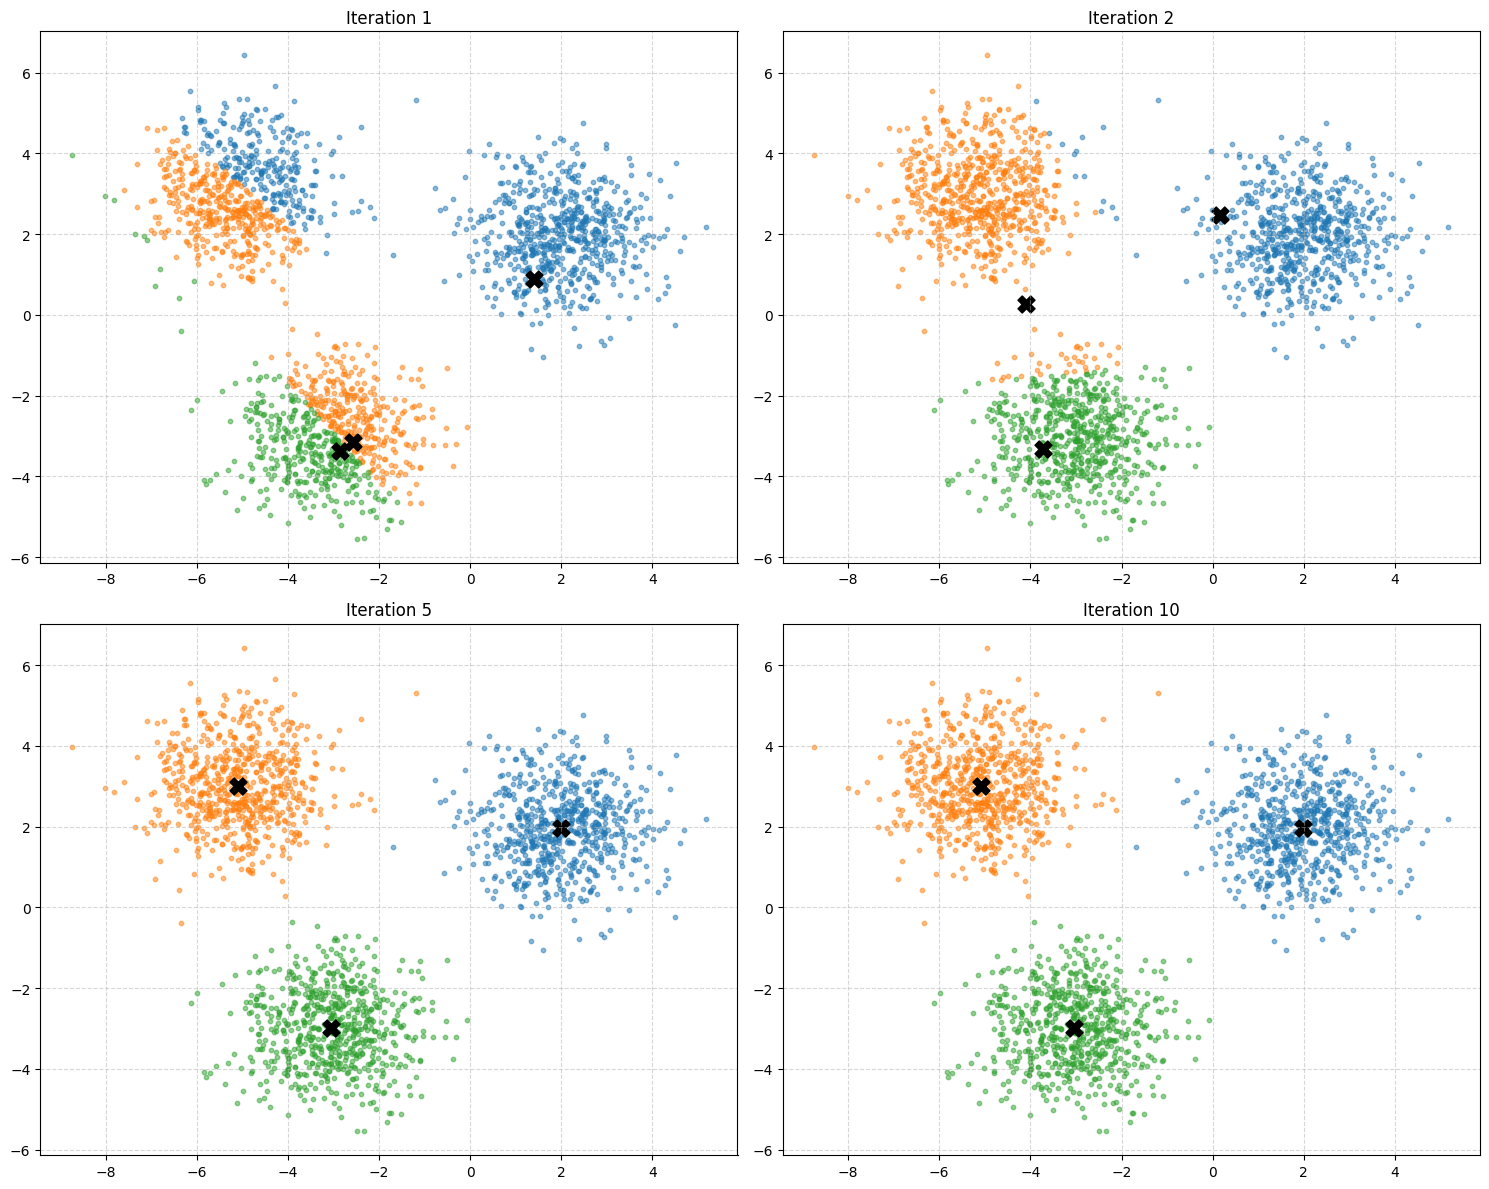

In [ ]:
# We perform k-means clustering for 10 iterations
current_centers = initial_centers.copy()

plt.figure(figsize=(15, 12))

for iteration in range(1, 11):
    # 1. Assign clusters
    current_z = assign_clusters(X, k, current_centers)

    # 2. Plot at specific iterations to see progression
    if iteration in [1, 2, 5, 10]:
        plt.subplot(2, 2, [1, 2, 5, 10].index(iteration) + 1)
        for cluster_idx in range(k):
            cluster_data = X[current_z == cluster_idx]
            plt.scatter(cluster_data[:, 0], cluster_data[:, 1], s=10, alpha=0.5)
        plt.scatter(current_centers[:, 0], current_centers[:, 1], c='black', marker='X', s=150)
        plt.title(f"Iteration {iteration}")
        plt.grid(True, linestyle='--', alpha=0.5)

    # 3. Compute new centers
    current_centers = compute_cluster_centers(X, current_z, k)

plt.tight_layout()
plt.show()